# Code Execution with Energy Profiling

In [14]:
# Import modules
import lassi.code_manager
import lassi.llm_methods
from lassi.get_power import report_gpu_memory
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

prompts = PromptDictionary()

In [2]:
folder = "test_codes/all-pairs-distance/"

# Source code
sourcecode_filename = "all-pairs-distance-cuda_main.cu"
with open(folder + "/" + sourcecode_filename, 'r') as file:
    source_code = file.read()
file.close()

# Code to test and input parameters
refactorcode_filename = "all-pairs-distance-cuda_main_ee_refactorcode_CUDA_exp_t14.3-idlecorr_pipelineV2_o3mini_allpairs_argo_ee_hecb_selfcontext_04-03-2025_t05_31_23_v0-baseLLM.cu"
with open(folder + "/" + refactorcode_filename, 'r') as file:
    refactored_code = file.read()
file.close()

# Parameters
exe_input_parameters = ["10000"]
power_measure = True
source_language = "CUDA"
target_language = "CUDA"
build_script = False
code_compiler = "nvcc"
code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
# -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s  # -arch=sm_60 for P100



----- > SOURCE CODE < -----
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main.cu', '-o', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main']

Compilation of code successful!

----- >>> System check BEFORE exe code...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 49.88 W, P0



Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: test_codes/all-pairs-distance
Execute command: ['./all-pairs-distance-cuda_main', '10000']


----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

CPU time: 120626.000000 (us)
Average kernel execution time: 167.281403 (us)
PASS
Average kernel execution time: 175.180298 (us)
PASS
Average kernel execution time: 169.152603 (us)
PASS

----- < END: Standard Output > -----

GPU power data has been written to CUDA_CUDA_gpu_net_power_results.csv


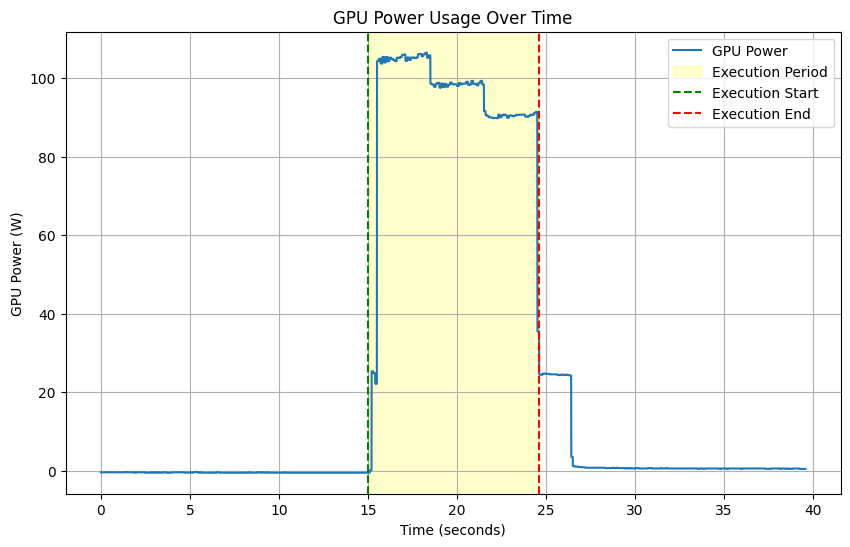

Start time: 15.001 -- End time: 24.579
Total GPU energy consumption for CUDA_CUDA_gpu_net_power_results.csv:
  0.000248 kWh
  0.2477 Wh
  891.83 J
Average GPU power: 93.19 W +/- 20.33 
 with sample standard deviation.
Total Energy During Exe Runtime:   891.83 J
Code execution duration:  9.58 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.76 W, P0




----- > REFACTORED CODE < -----
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main_ee_refactorcode_CUDA_exp_t14.3-idlecorr_pipelineV2_o3mini_allpairs_argo_ee_hecb_selfcontext_04-03-2

Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: test_codes/all-pairs-distance
Execute command: ['./all-pairs-distance-cuda_main_ee_refactorcode_CUDA_exp_t14.3-idlecorr_pipelineV2_o3mini_allpairs_argo_ee_hecb_selfcontext_04-03-2025_t05_31_23_v0-baseLLM', '10000']


----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

CPU time: 118901 (us)
Kernel k1 average execution time: 124.031700 (us)
Kernel k1 verification: PASS
Kernel k2 average execution time: 132.683182 (us)
Kernel k2 verification: PASS
Kernel k3 average execution time: 123.644264 (us)
Kernel k3 verification: PASS

----- < END: Standard Output > -----

GPU power data has been written to CUDA_CUDA_gpu_net_power_results.csv


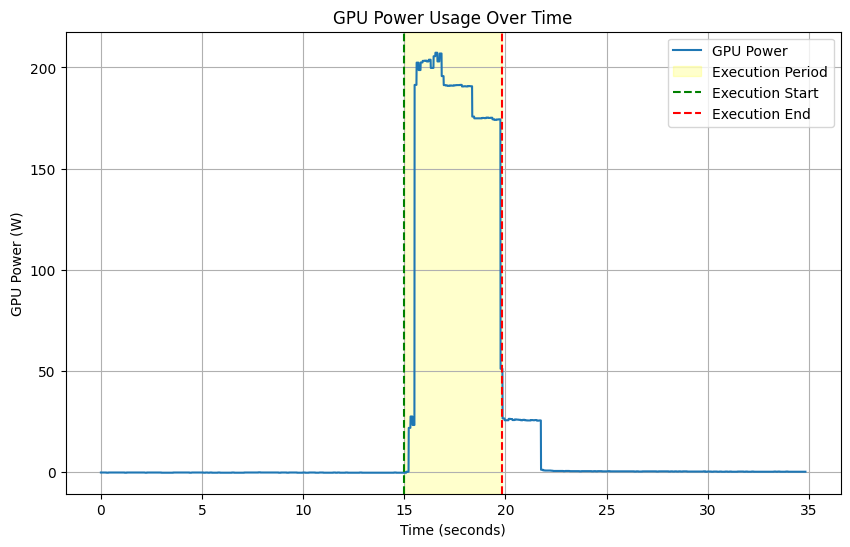

Start time: 15.001 -- End time: 19.828
Total GPU energy consumption for CUDA_CUDA_gpu_net_power_results.csv:
  0.000227 kWh
  0.2266 Wh
  815.82 J
Average GPU power: 169.25 W +/- 56.23 
 with sample standard deviation.
Total Energy During Exe Runtime:   815.82 J
Code execution duration:  4.83 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.05 W, P0



In [3]:
# Compile and execute source and refactored codes

print("\n\n----- > SOURCE CODE < -----")
source_compile_result, source_execute_file = lassi.code_manager.compile_code(
    folder + '/' + sourcecode_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

# Execute code with Energy Profiling
source_execute_result, source_exe_output, source_total_energy_joules, source_ave_power, source_std_power, source_duration, source_metrics_results_string = lassi.code_manager.execute_code(
    source_execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=5
)

print("\n==================================================")

print("\n\n----- > REFACTORED CODE < -----")
refactored_compile_result, refactored_execute_file = lassi.code_manager.compile_code(
    folder + '/' + refactorcode_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

# Execute code with Energy Profiling
refactored_execute_result, refactored_exe_output, refactored_total_energy_joules, refactored_ave_power, refactored_std_power, refactored_duration, refactored_metrics_results_string = lassi.code_manager.execute_code(
    refactored_execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=5
)

## Optional - Measure system idle power
Using same runtime as code execution above.

Measure system idle power...
Duration for idle time measurement: 9.62
GPU power data has been written to idle__gpu_net_power_results.csv


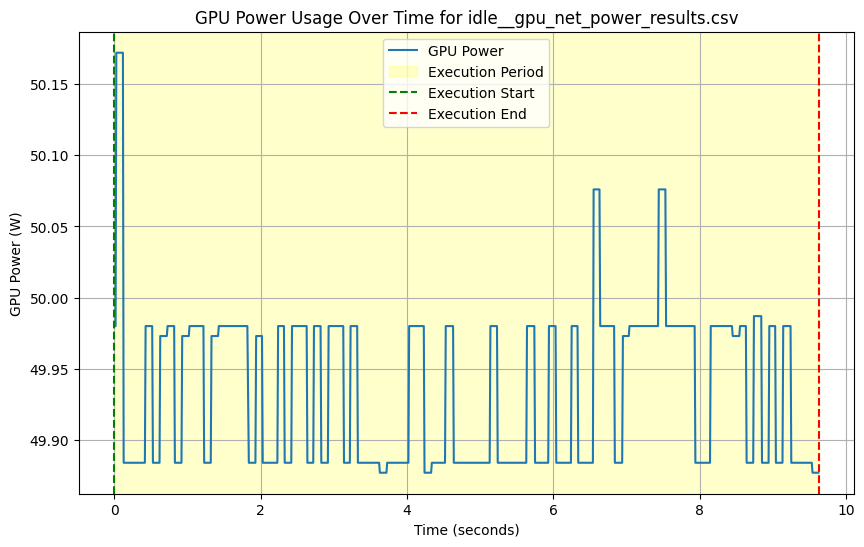

Start time: 0 -- End time: 9.624
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000134 kWh
  0.1336 Wh
  480.89 J
Average GPU power: 49.94 W
 with sample standard deviation: 0.06
Total Energy During Exe Runtime:   480.89 J
Code execution duration: 9.62 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Idle power measured values for same runtime as all-pairs-distance-cuda_main.cu
Average GPU power: 49.94 W +/- 0.06
Total Energy During Code Runtime: 480.89 J


In [5]:
# OPTIONAL
# Measure system idle power
print("Measure system idle power...")
idle_energy_joules, idle_ave_power, std_idle_ave_power = lassi.get_power.idlepower(duration)
idlecorrected_energy = total_energy_joules - idle_energy_joules
idlecorrected_ave_power = ave_power - idle_ave_power
print(color.BOLD + color.BLUE + "\nIdle power measured values for same runtime as " + color.END + str(code_filename))
print("Average GPU power: " + color.BOLD + f"{idle_ave_power:.2f} W +/- {std_idle_ave_power}" + color.END)
print("Total Energy During Code Runtime: " + color.BOLD + f"{idle_energy_joules:.2f} J" + color.END)

# LASSI Code Evaluation

In [12]:
# Run valid code check with LLM-as-as-Judge

llm_source = "argo"
model = "gpto3mini"
num_ctx = 20000
display_response = True
verifyprompt = False  # set to True to view the LLM prompt in output below

system_prompt = prompts.get_system_prompt("general_system_ee")

# Build code comparison data
input_content_llmjudge_dict = {
    "source_code": source_code,
    "source_stdout": source_exe_output,
    "source_metrics": source_metrics_results_string,
    "refactored_code": refactored_code,
    "refactored_stdout": refactored_exe_output,
    "refactored_metrics": refactored_metrics_results_string,
} 

# Call LLM-as-a-judge to review SOURCE CODE and REFACTORED CODE
# to evaluate if potentially valid
valid_code_flag = lassi.llm_methods.llm_judge(
    llm_source,
    model,
    num_ctx,
    system_prompt,
    input_content_llmjudge_dict,
    display_response,
    verifyprompt
)

print(color.BOLD + "\n===> Result: " + color.BLUE + f"{valid_code_flag}\n\n" + color.END)



--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



The refactored code preserves the core functionality of the source code. Both versions:
• Compute the same all-pairs distance calculation on the data.
• Compare the GPU computed distances with the CPU computed distances using memcmp.
• Launch three different kernels (k1, k2, k3) that ultimately produce identical PASS/FAIL verification messages.

The differences lie only in the non-functional aspects aimed at energy efficiency. For example:
 – The refactored code uses cudaMemset to zero device memory instead of the two-step bzero + cudaMemcpy.
 – It allocates pinned host memory to speed up transfers and lower CPU overhead.
 – It replaces gettimeofday timing for GPU kernels with CUDA events, which not only reduces CPU overhead but reports average kernel times slightly differently in wording.
These changes change the layout of the printed messages (e.g., "Kernel k1 average execution time:" vs. "Average kernel execution time:"), and the measured timings differ (e.g., slightly lower or higher numbers) but the functionality and the core output verification (“PASS”) remain exactly the same.

Based on these observations, the refactored code is functionally equivalent. 

VALID



----- END LLM RESPONSE -----


===> Result: VALID




In [13]:
# Run code comparison check

print("\n\n----- " + color.BOLD + color.BLUE + "FINAL CODE COMPARISON: Source Code vs. Best Refactored Code" + color.END + " -----\n")
        
compare_code = prompts.get_code_comparison("cuda_cpp")
compare_code = compare_code + "\n\n" + "[BEGIN SOURCE CODE AND RESULTS]\n\n" + input_content_llmjudge_dict["source_code"]
compare_code = compare_code + "\n\nOUTPUT: \n\n" + input_content_llmjudge_dict["source_stdout"]
compare_code = compare_code + "\n\nCode execution duration: " + str(round(source_duration, 2)) + " s"
compare_code = compare_code + "\nTotal Energy Consumed: " + str(round(source_total_energy_joules,2)) + " J" + "\nAverage Power: " + str(round(source_ave_power,2)) + " W"
compare_code = compare_code + "\n\n[/END SOURCE CODE AND RESULTS]"
        
compare_code = compare_code + "\n\n" + "[BEGIN REFACTORED CODE AND RESULTS]\n\n" + input_content_llmjudge_dict["refactored_code"]
compare_code = compare_code + "\n\nOUTPUT: \n\n" + input_content_llmjudge_dict["refactored_stdout"]
compare_code = compare_code + "\n\nCode execution duration: " + str(round(refactored_duration, 2)) + " s"
compare_code = compare_code + "\nTotal Energy Consumed: " + str(round(refactored_total_energy_joules,2)) + " J" + "\nAverage Power: " + str(round(refactored_ave_power,2)) + " W"
compare_code = compare_code + "\n\n[/END REFACTORED CODE AND RESULTS]"

# Send prompt to LLM endpoint
print("\n" + color.GREEN + "--> ... " + color.UNDERLINE + "LLM prompt to compare codes." + color.END + "\n\n")
code_comparison_response = lassi.llm_methods.llm_call("code comparison", llm_source, model, num_ctx, system_prompt, compare_code, display_response, verifyprompt)



----- FINAL CODE COMPARISON: Source Code vs. Best Refactored Code -----


--> ... LLM prompt to compare codes.



=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code comparison -----



```
Key energy‐efficiency improvements in the refactored code include:

• Instead of using a bzero followed by cudaMemcpy to initialize (zero) the output buffers on the device, the refactored code calls cudaMemset. This reduces CPU overhead and the number of memory copy operations, limiting unnecessary energy usage on the host.

• The refactored version allocates host memory using cudaMallocHost (pinned, page‐locked memory). Pinned memory speeds up host‐to‐device transfers and reduces CPU waiting, thereby lowering CPU power consumption during data transfers.

• GPU timing is handled using CUDA events (along with a helper templated launchKernel function) rather than gettimeofday. Using CUDA events offloads timing to the GPU, minimizing CPU busy‐wait loops and reducing CPU energy consumption.

• CPU timing is modernized with std::chrono instead of OS gettimeofday calls. This modern timing approach can be more efficient and may reduce overhead.

• The repetitive pattern of launching kernels is modularized into a helper template function. This eliminates code duplication and may help the compiler optimize resource management, reducing both CPU and GPU power usage.

These changes all aim to lower the overall CPU overhead (by streamlining memory initialization and timing) and reduce host–device transfer latency, which in turn contributes to reduced total energy consumption during execution. The kernel implementations are functionally equivalent; the refactoring focuses on the host-side infrastructure for improving energy efficiency.
```